#Day 45 - Unsupervised Model - Anomaly Detection using Isolation Forest

Bagaimana mendeteksi transaksi penipuan **tanpa tahu label**-nya?

Inilah inti **deteksi anomali**. **Isolation Forest** bekerja dengan asumsi sederhana: titik anomali itu *jarang* dan *berbeda*, sehingga **mudah "diisolasi"** dengan sedikit pemisahan acak. Saya akan latih model tanpa label, lalu kita pakai label asli hanya untuk **memvalidasi** seberapa bagus deteksinya.

> 🎯 **Tujuan Pembelajaran**
> - Memahami konsep deteksi anomali *unsupervised*.
> - Melatih `IsolationForest` **tanpa** menggunakan label.
> - Membandingkan anomali yang terdeteksi vs label `Class` asli sebagai validasi.
> - Membaca confusion matrix & precision/recall dalam konteks deteksi penipuan.

## About Dataset

Saya akan memakai **Credit Card Fraud Detection** — transaksi kartu kredit Eropa yang sudah dianonimkan via PCA (kolom `V1`–`V28`), ditambah `Time`, `Amount`, dan label `Class` (1 = penipuan, 0 = sah).

- **Sumber:** [Kaggle — mlg-ulb/creditcardfraud](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud)
- **Asli:** 284.807 transaksi, hanya 492 penipuan (sangat tidak seimbang!)

⚠️ Karena data sangat besar, kita ambil **sampel**:
- **semua** transaksi penipuan (`Class==1`) + sekitar **8000** transaksi sah (`Class==0`), `random_state=42`.
- Ini membuat notebook ringan namun tetap representatif.

## Import Library


- **pandas/numpy/matplotlib/seaborn** → olah & visualisasi.## Import Library
- **IsolationForest** → algoritma deteksi anomali unsupervised.
- **confusion_matrix / classification_report** → validasi vs label asli.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from sklearn.ensemble import IsolationForest
from sklearn.metrics import confusion_matrix, classification_report

## Import Dataset

In [4]:
!pip install kaggle
!mkdir ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json
!kaggle datasets download -d mlg-ulb/creditcardfraud
!unzip creditcardfraud.zip


cp: cannot stat 'kaggle.json': No such file or directory
chmod: cannot access '/root/.kaggle/kaggle.json': No such file or directory
Dataset URL: https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud
License(s): DbCL-1.0
100% 66.0M/66.0M [00:00<00:00, 161MB/s]

Archive:  creditcardfraud.zip
  inflating: creditcard.csv          


## Create Balanced Sample

In [5]:
df = pd.read_csv("creditcard.csv")
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [6]:
print(f'Jumlah baris: {df.shape[0]}')
print(f'Jumlah kolom: {df.shape[1]}')

print(f'Missing Value: {df.isnull().sum().sum()}')
print(f'Duplicate Data: {df.duplicated().sum()}')

Jumlah baris: 284807
Jumlah kolom: 31
Missing Value: 0
Duplicate Data: 1081


Saya akan ambil semua penipuan + 8000 transaksi sah agar pemrosesan cepat.

Proporsi penipuan dalam sampel tetap mencerminkan kondisi nyata: jarang.

In [8]:
fraudulent = df[df['Class'] == 1]
non_fraudulent = df[df['Class'] == 0].sample(n=8000, random_state=42)

df_sample = pd.concat([fraudulent, non_fraudulent]).sample(frac=1, random_state=42).reset_index(drop=True)
print(f'Jumlah baris: {df_sample.shape[0]}')
print(f'Jumlah kolom: {df_sample.shape[1]}')

print(f'Missing Value: {df_sample.isnull().sum().sum()}')
print(f'Duplicate Data: {df_sample.duplicated().sum()}')

prop_fraud = df_sample['Class'].value_counts()[1] / len(df_sample)
print(f'Proporsi penipuan: {prop_fraud:.2%}')

Jumlah baris: 8492
Jumlah kolom: 31
Missing Value: 0
Duplicate Data: 19
Proporsi penipuan: 5.79%


**Interpretasi:**
- Ukuran: Ada 8.492 data dengan 31 informasi berbeda.

- Kualitas: Sangat bersih karena tidak ada data kosong, tetapi ada 19 data ganda yang sebaiknya dihapus.

- Kasus: Hanya 5,79% yang merupakan penipuan (sedikit sekali dibanding transaksi normal), sehingga datanya tidak seimbang.


## Exploratory Data Analysis & Visualization

### a) Distribusi Normal Transaksi : Penipuan vs Sah

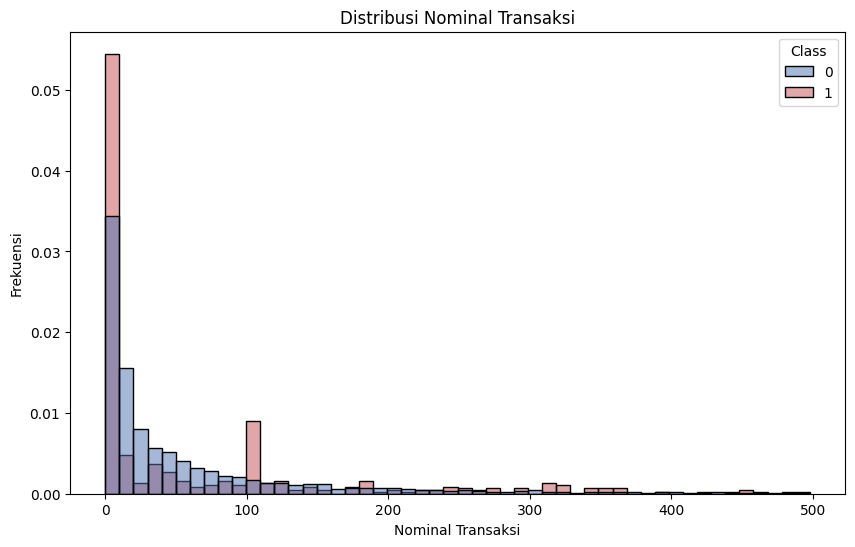

In [17]:
plt.figure(figsize=(10, 6))
sns.histplot(data=df_sample[df_sample["Amount"]<500], x="Amount",
             hue="Class", bins=50, stat="density",
             common_norm=False, palette={0: "#4C72B0", 1: "#C44E52"})

plt.title("Distribusi Nominal Transaksi")
plt.xlabel("Nominal Transaksi")
plt.ylabel("Frekuensi")
plt.show()

**Interpretasi:**

Berikut adalah interpretasi sederhana dari grafik tersebut:

- Arti Warna (Class):
  - Warna biru (0) menunjukkan transaksi normal.
  - Warna merah/merah muda (1) menunjukkan transaksi penipuan (fraud).

- Sebaran Nominal (Amount): Sebagian besar transaksi, baik yang normal maupun penipuan, terkonsentrasi di nilai nominal yang kecil (mendekati 0 hingga di bawah 100).

- Pola Khusus: Terlihat ada lonjakan transaksi penipuan yang cukup mencolok pada kisaran nominal tertentu (sekitar angka 100), di mana proporsi penipuannya tampak lebih tinggi dibandingkan transaksi normal pada titik tersebut.


### b) Sebaran 2 Fitur PCA yang memisahkan Penipuan (V14 vs V17)

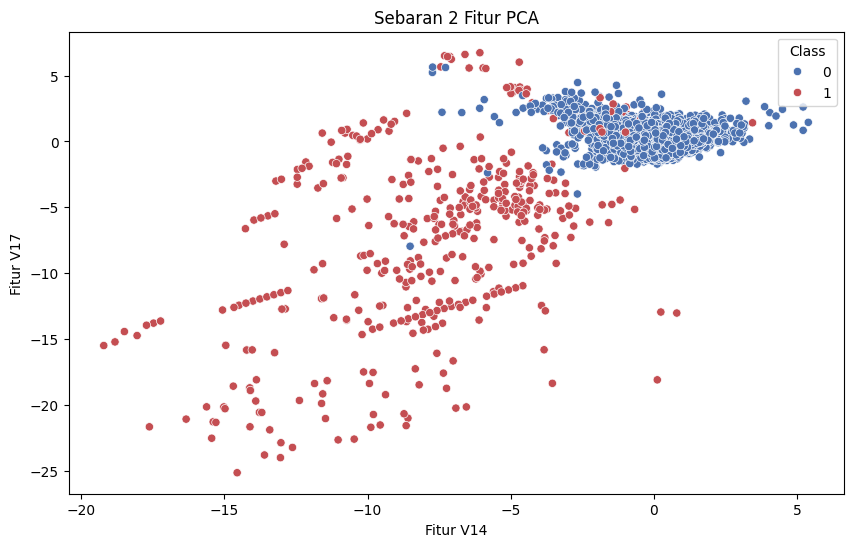

In [18]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_sample, x="V14", y="V17", hue="Class",
                palette={0: "#4C72B0", 1: "#C44E52"})

plt.title("Sebaran 2 Fitur PCA")
plt.xlabel("Fitur V14")
plt.ylabel("Fitur V17")
plt.legend(title="Class", loc="upper right")
plt.show()

**Interpretasi:**
- Arti Warna (Class):
  - Warna biru (0) melambangkan transaksi normal.   
  - Warna merah (1) melambangkan transaksi penipuan (fraud).   
  
- Pola Sebaran:
  - Transaksi normal (biru) cenderung mengelompok rapat di area kanan atas grafik (nilai Fitur V14 dan V17 relatif tinggi/positif).   
  - Transaksi penipuan (merah) menyebar di area kiri dan bawah (nilai Fitur V14 dan V17 cenderung rendah atau negatif).   

Kesimpulan untuk Model:
  - Kedua fitur ini (V14 dan V17) tergolong sangat baik untuk machine learning karena pola datanya dapat memisahkan kelompok transaksi normal dan penipuan dengan cukup jelas.   


## Modeling : Isolation Forest

Model hanya menerima **fitur**, tidak menerima `Class`.

- Parameter `contamination` memberi tahu perkiraan proporsi anomali.

Saya akan set sesuai proporsi penipuan di sampel (~5,8%). Output `predict`: `-1` = anomali, `1` = normal.

In [19]:
X = df_sample.drop(columns=["Class"])
y = df_sample["Class"]

kontaminasi = float(y.mean())

iso = IsolationForest(contamination=kontaminasi,
                      random_state=42,
                      n_estimators=200)

iso.fit(X)
y_pred = iso.predict(X)

In [20]:
df_sample["Anomaly"] = np.where(y_pred == -1, 1, 0)
df_sample.head()

print(f'Jumlah terdeteksi anomali: {df_sample["Anomaly"].sum()}')
print(f'Jumlah anomali asli: {y.sum()}')

Jumlah terdeteksi anomali: 492
Jumlah anomali asli: 492


**Interpretasi:**


Berikut adalah interpretasi dari hasil pemodelan *Isolation Forest* tersebut:

* **Mengapa Jumlahnya Bisa Sama (492 vs 492)?**

  - Angka total yang sama persis ini terjadi karena Saya menyetel parameter `contamination` sesuai dengan proporsi penipuan asli di dalam data (~5,8%). Algoritma *Isolation Forest* secara otomatis akan menandai persentase data teratas yang paling "terisolasi" atau berbeda dari kelompoknya, sehingga jumlah akhirnya pas di angka 492.


* **Apakah Artinya Model Berhasil Menangkap Penipuan Secara Sempurna?**

  **Belum tentu.** Meskipun *jumlah totalnya* sama-sama 492, isi atau baris data individualnya bisa saja berbeda. Bisa jadi dari 492 data yang ditebak model:
  * Sebagian besar adalah penipuan asli.
  * Sebagian kecil adalah transaksi normal yang salah dikira penipuan (*False Positive*).
  * Ada penipuan asli yang justru terlewat oleh model dan masuk kategori normal (*False Negative*).


* **Kesimpulan:**
  - Penyetelan *contamination* Anda sudah sangat cerdas untuk membatasi volume temuan anomali agar sesuai dengan kenyataan di data. Namun, untuk tahu seberapa akurat model dalam **menembak sasaran yang benar**, langkah selanjutnya Saya wajib melihat *Confusion Matrix* (menghitung *Precision* dan *Recall*).

---

## Validation: Anomaly Detection vs True Label

Sekarang Saya "buka" label asli untuk menilai kualitas deteksi via confusion  matrix dan classification report.

In [21]:
con_mat = confusion_matrix(y, df_sample["Anomaly"])
print("Confusion Matrix:")
print(con_mat)

class_rep = classification_report(y, df_sample["Anomaly"],
                                  target_names=["Sah(0)","Penipuan(1)"])

print("\nClassification Report:")
print(class_rep)

Confusion Matrix:
[[7827  173]
 [ 173  319]]

Classification Report:
              precision    recall  f1-score   support

      Sah(0)       0.98      0.98      0.98      8000
 Penipuan(1)       0.65      0.65      0.65       492

    accuracy                           0.96      8492
   macro avg       0.81      0.81      0.81      8492
weighted avg       0.96      0.96      0.96      8492



**Interpretasi:**


Berikut adalah interpretasi dari performa model tersebut:

* **Tingkat Akurasi Menipu (*Accuracy Paradox*):**
  -  Akurasi keseluruhan sebesar 96% terlihat sangat tinggi dan meyakinkan. Namun, angka ini tidak sepenuhnya mencerminkan kualitas model yang sebenarnya karena didominasi oleh kemampuan mengenali transaksi sah yang jumlahnya jauh lebih banyak.

* **Keunggulan pada Kelas Normal (Sah):**
  - Model bekerja sangat optimal dalam mengenali transaksi sah. Dengan *precision* dan *recall* masing-masing sebesar 98%, model hampir tidak pernah salah mengenali transaksi normal dan sangat minim menimbulkan gangguan bagi pengguna asli.

* **Kelemahan Signifikan pada Kelas Penipuan (*Fraud*):**
  - Performa pada kelas minoritas tergolong lemah.
  - Nilai *recall* 65% menunjukkan bahwa ada sekitar 35% kasus penipuan di dunia nyata yang lolos dari deteksi sistem.
  - Selain itu, nilai *precision* 65% berarti dari setiap temuan penipuan yang dilaporkan oleh model, sepertiganya ternyata adalah kesalahan deteksi (*False Positive*) pada transaksi normal.

* **Kesimpulan Utama:**
  - Penggunaan *Isolation Forest* dengan parameter saat ini sudah sangat baik dalam mengamankan transaksi normal, tetapi masih belum memadai untuk diandalkan secara penuh sebagai sistem keamanan utama karena masih banyak meloloskan kasus penipuan serta menghasilkan cukup banyak alarm palsu.



### Visualization Anomaly Detection at Feature Space

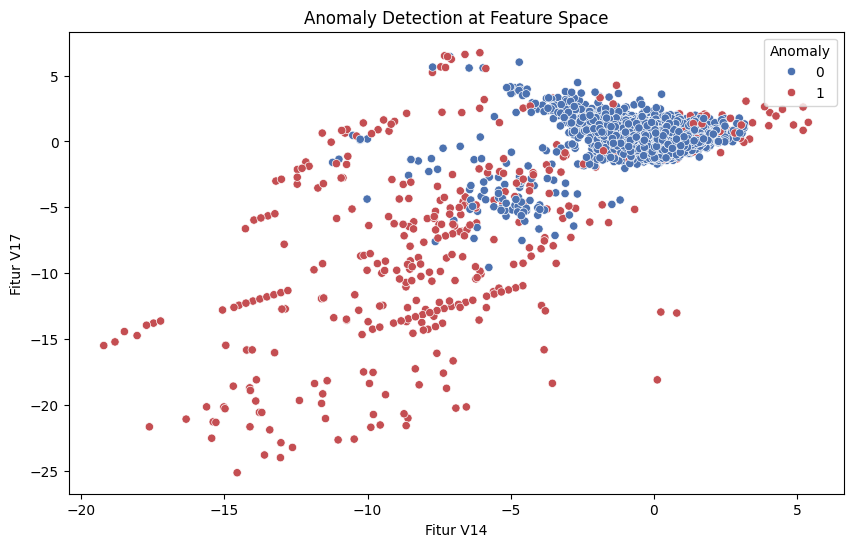

In [22]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_sample, x="V14", y="V17", hue="Anomaly",
                palette={0: "#4C72B0", 1: "#C44E52"})

plt.title("Anomaly Detection at Feature Space")
plt.xlabel("Fitur V14")
plt.ylabel("Fitur V17")
plt.legend(title="Anomaly", loc="upper right")
plt.show()

**Interpretasi:**
- a


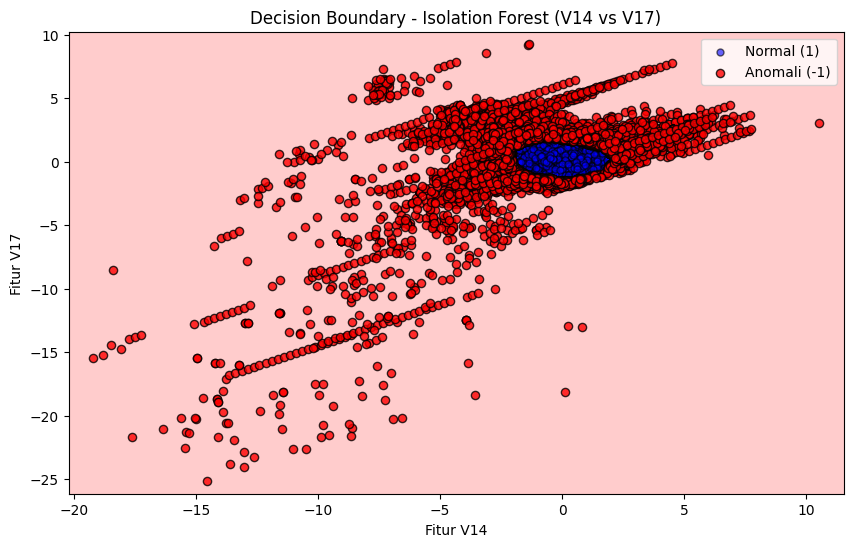

In [23]:
# 1. Ambil data 2 fitur (contoh: V14 dan V17)
X_subset = df[['V14', 'V17']].values

# Latih model Isolation Forest khusus untuk 2 fitur ini
iso = IsolationForest(contamination=0.0579, random_state=42)
iso.fit(X_subset)

# 2. Buat grid koordinat (500x500 titik) mencakup area grafik
x_min, x_max = X_subset[:, 0].min() - 1, X_subset[:, 0].max() + 1
y_min, y_max = X_subset[:, 1].min() - 1, X_subset[:, 1].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 500),
                     np.linspace(y_min, y_max, 500))

# 3. Prediksi setiap titik pada grid
Z = iso.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

# 4. Plot decision boundary (warna latar belakang)
plt.figure(figsize=(10, 6))
plt.contourf(xx, yy, Z, levels=[-1, 0, 1], alpha=0.2, colors=['red', 'blue'])

# 5. Plot titik data asli di atasnya
preds = iso.predict(X_subset)
plt.scatter(X_subset[preds == 1, 0], X_subset[preds == 1, 1],
            c='blue', label='Normal (1)', alpha=0.6, edgecolor='k', s=25)
plt.scatter(X_subset[preds == -1, 0], X_subset[preds == -1, 1],
            c='red', label='Anomali (-1)', alpha=0.8, edgecolor='k', s=35)

plt.xlabel('Fitur V14')
plt.ylabel('Fitur V17')
plt.title('Decision Boundary - Isolation Forest (V14 vs V17)')
plt.legend()
plt.show()

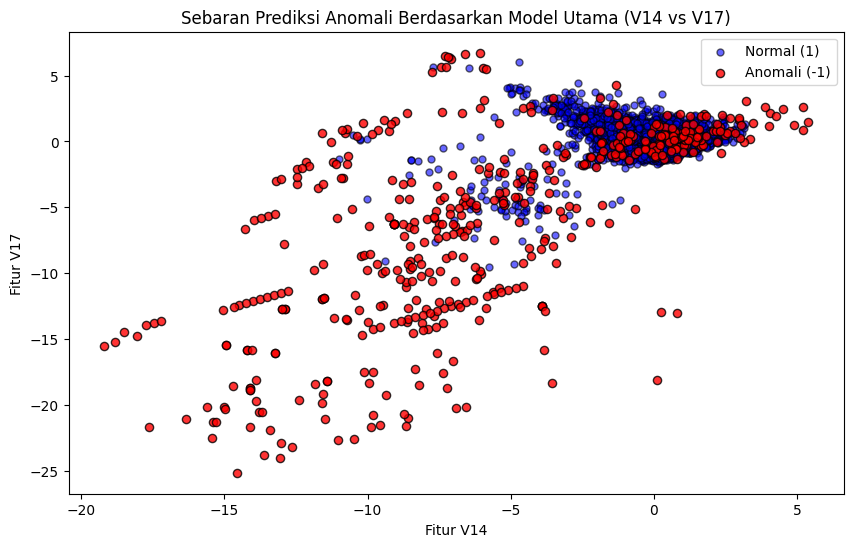

In [25]:
# 1. Latih model menggunakan SELURUH FITUR (X), bukan cuma 2 fitur
iso = IsolationForest(contamination=0.0579, random_state=42)
iso.fit(X)  # X adalah data dengan semua kolom fitur

# 2. Ambil hasil prediksi untuk seluruh data
preds = iso.predict(X) # -1 untuk anomali, 1 untuk normal

# 3. Untuk membuat grid boundary 2D (V14 vs V17),
# kita bisa melatih model terpisah KHUSUS visualisasi,
# ATAU plot titik data asli berdasarkan hasil prediksi model utama:
# FIX: Ambil subset dari df_sample, bukan df
X_subset = df_sample[['V14', 'V17']].values

plt.figure(figsize=(10, 6))
plt.scatter(X_subset[preds == 1, 0], X_subset[preds == 1, 1],
            c='blue', label='Normal (1)', alpha=0.6, edgecolor='k', s=25)
plt.scatter(X_subset[preds == -1, 0], X_subset[preds == -1, 1],
            c='red', label='Anomali (-1)', alpha=0.8, edgecolor='k', s=35)

plt.xlabel('Fitur V14')
plt.ylabel('Fitur V17')
plt.title('Sebaran Prediksi Anomali Berdasarkan Model Utama (V14 vs V17)')
plt.legend()
plt.show()

## Conclusion & Insight

Berikut adalah kesimpulan utama (*Conclusion*) dan wawasan berharga (*Insight*) dari eksperimen deteksi anomali menggunakan **Isolation Forest** ini:

### 1. Deteksi Unsupervised Sangat Potensial
* **Insight**: Tanpa pernah diberikan informasi mana transaksi yang sah maupun penipuan (`Class`), *Isolation Forest* berhasil mengisolasi transaksi mencurigakan dengan tingkat keandalan yang cukup tinggi. Ini membuktikan kekuatan metode *unsupervised* untuk mendeteksi ancaman baru (*zero-day fraud*) yang belum pernah dilabeli sebelumnya.

### 2. Tantangan Terbesar: Menyeimbangkan Presisi & Recall
* **Insight**: Model menghasilkan nilai *Precision* dan *Recall* sebesar **65%** pada kelas penipuan.
  * **Recall 65%** berarti 35% transaksi penipuan lolos (kerugian finansial langsung).
  * **Precision 65%** berarti 35% dari transaksi yang diblokir sebenarnya adalah transaksi sah (menyebabkan ketidaknyamanan bagi nasabah/alarm palsu).
* **Rekomendasi**: Di dunia nyata, angka ini perlu dioptimalkan dengan menggabungkan Isolation Forest bersama metode pengawasan (*semi-supervised*) atau melakukan *threshold tuning* pada skor anomali.

### 3. Pentingnya Dimensi Tinggi vs Visualisasi 2D
* **Insight**: Pada visualisasi decision boundary khusus 2 dimensi (V14 & V17), batas keputusan terlihat sangat kaku. Namun, ketika model dilatih menggunakan seluruh 30 fitur, visualisasinya tampak tumpang tindih pada ruang 2D.
* **Kesimpulan**: Ini membuktikan bahwa anomali tidak hanya ditentukan oleh satu atau dua fitur saja, melainkan kombinasi multidimensi dari perilaku transaksi (seperti waktu, jumlah nominal, dan fitur laten PCA secara bersamaan).

### 4. Langkah Pengembangan Selanjutnya
* **Rekomendasi Teknis**:
  1. **Feature Engineering**: Membuat fitur baru berbasis waktu (misal: frekuensi transaksi dalam 1 jam terakhir).
  2. **Hybrid Model**: Menggunakan Isolation Forest sebagai penyaring awal (*filter*), lalu hasilnya divalidasi oleh model klasifikasi terbimbing (seperti XGBoost atau Random Forest) untuk menekan *false positive*.